# 01 — Exploratory analysis

This notebook displays the Stage 1 EDA artifacts. It does not recompute them.
Run `python -m src.preprocess` and `python -m src.eda` first.

The evaluation split is the official AVeriTeC dev set. Justification text is not a feature.


In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import config as C
from src.utils import read_json

report = read_json(C.PREPROCESS_REPORT)
report


{'source': 'chenxwh_hf',
 'train': {'loaded': 3068,
  'dropped_invalid': 1,
  'dropped_duplicates': 71,
  'final': 2996,
  'missing_evidence_share': 0.0,
  'class_counts': {'Supported': 809,
   'Refuted': 1727,
   'Not Enough Evidence': 268,
   'Conflicting Evidence/Cherrypicking': 192}},
 'test': {'loaded': 500,
  'dropped_invalid': 0,
  'dropped_duplicates': 9,
  'removed_train_overlap': 4,
  'final': 487,
  'missing_evidence_share': 0.0,
  'class_counts': {'Supported': 111,
   'Refuted': 305,
   'Not Enough Evidence': 33,
   'Conflicting Evidence/Cherrypicking': 38}}}

## Class summary

One row per split and label: how common the class is, how long the claim and evidence are, and how often evidence is missing.


In [2]:
summary = pd.read_csv(C.TABLES_DIR / "eda_summary.csv")
summary


,split,label,count,share,mean_claim_len,mean_evidence_len,missing_evidence_share
0,train,Supported,809,0.270027,17.022250,116.414091,0.0
1,train,Refuted,1727,0.576435,17.042270,123.307470,0.0
2,train,Not Enough Evidence,268,0.089453,18.305970,109.294776,0.0
3,train,Conflicting Evidence/Cherrypicking,192,0.064085,16.010417,210.427083,0.0
4,test,Supported,111,0.227926,16.666667,115.657658,0.0
5,test,Refuted,305,0.626283,17.524590,146.921311,0.0
6,test,Not Enough Evidence,33,0.067762,17.484848,128.424242,0.0
7,test,Conflicting Evidence/Cherrypicking,38,0.078029,20.394737,182.552632,0.0


## Figures

The phrase figure is the annotation-shortcut check. A high share of "no answer" wording on Not Enough Evidence means a model can score that class without reading the claim.


**eda_class_distribution.png**

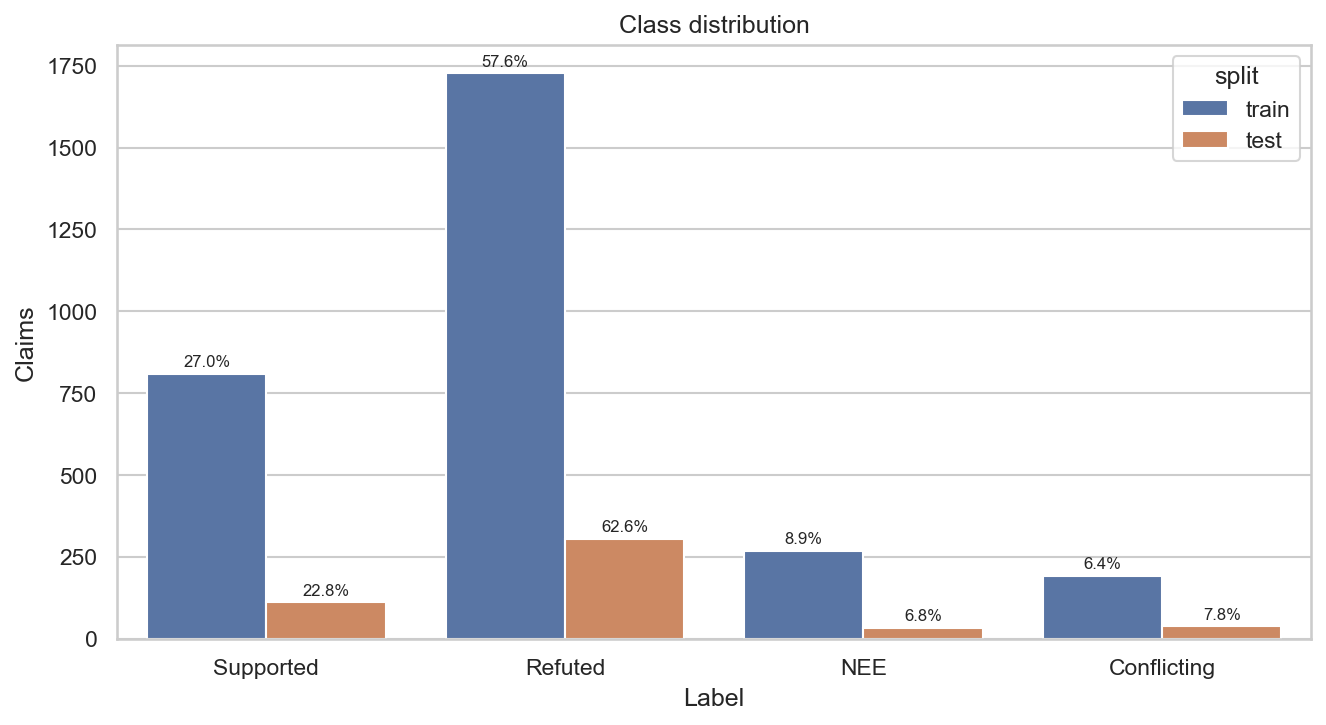

**eda_claim_length.png**

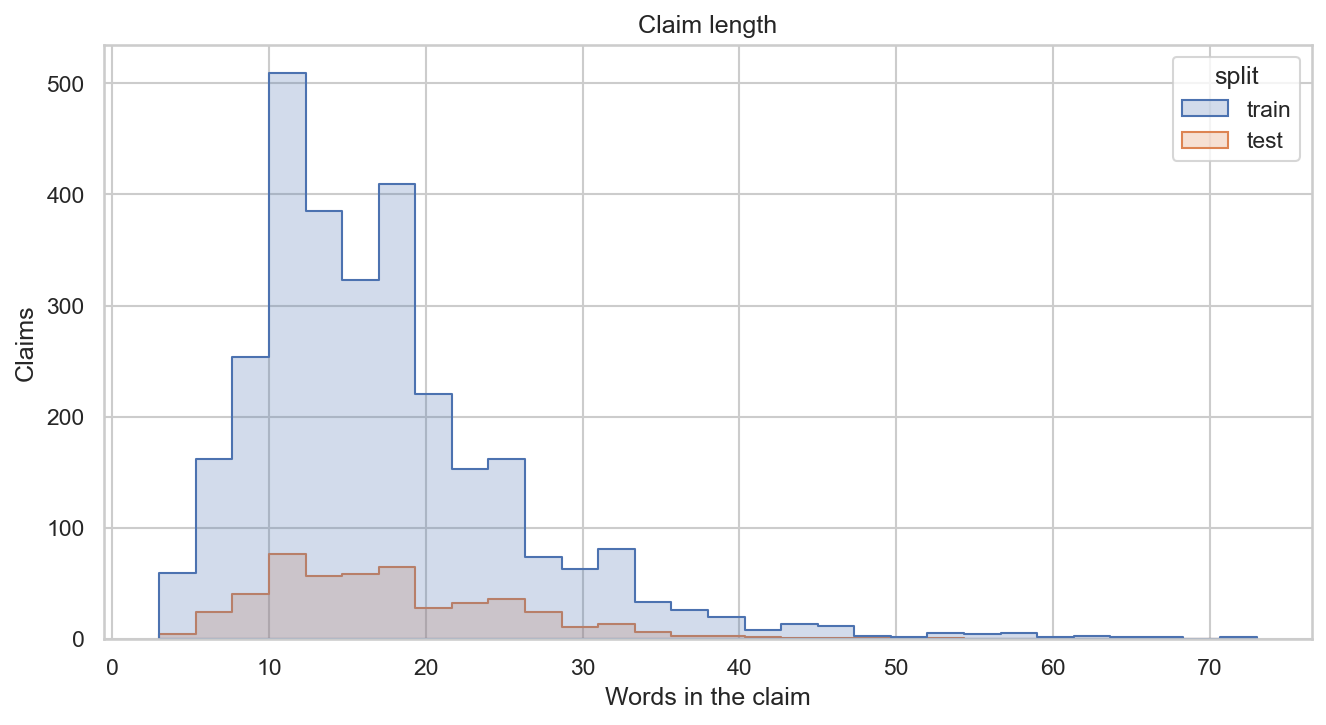

**eda_evidence_length.png**

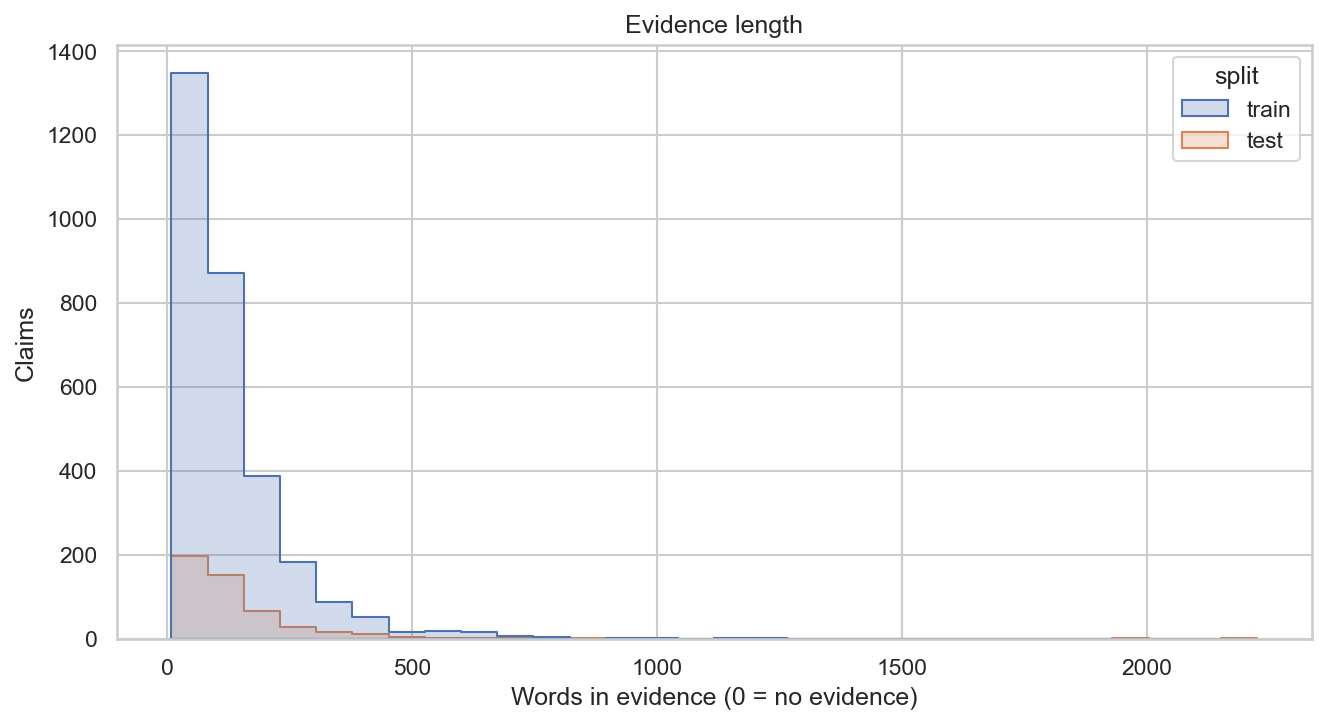

**eda_missing_evidence_by_class.png**

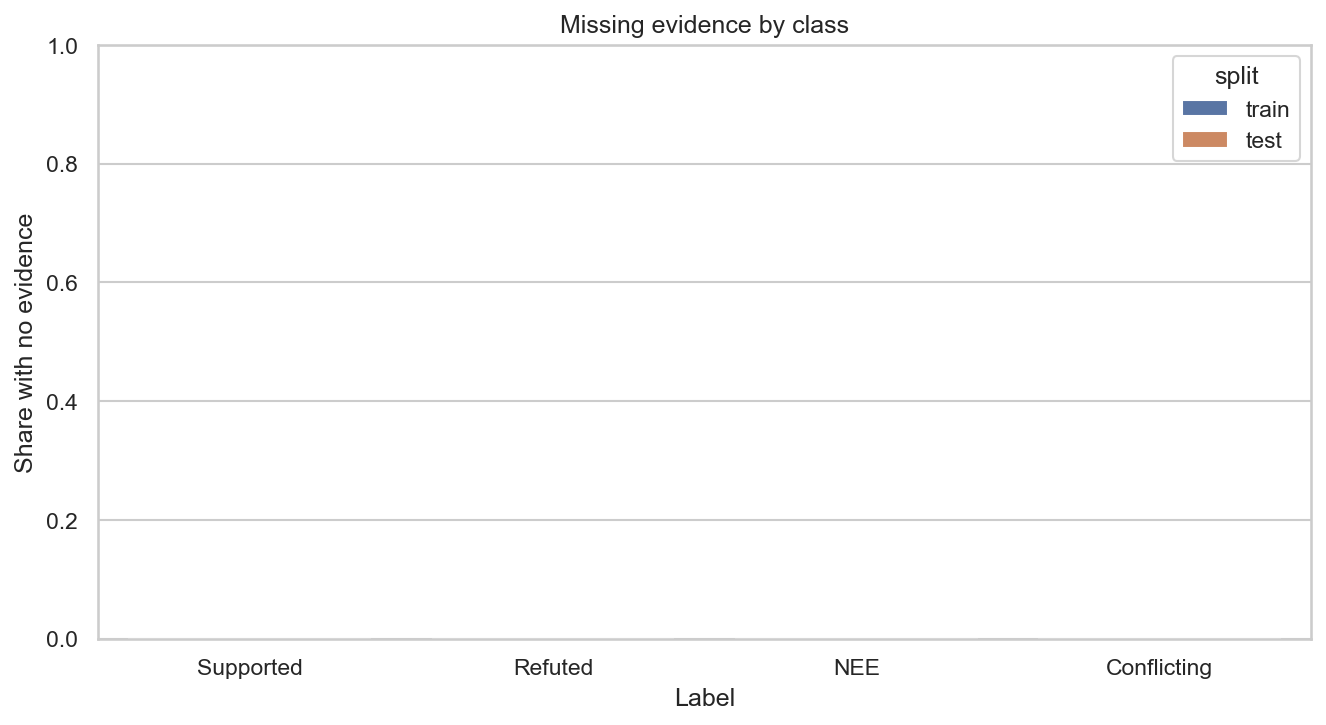

**eda_n_qa_by_class.png**

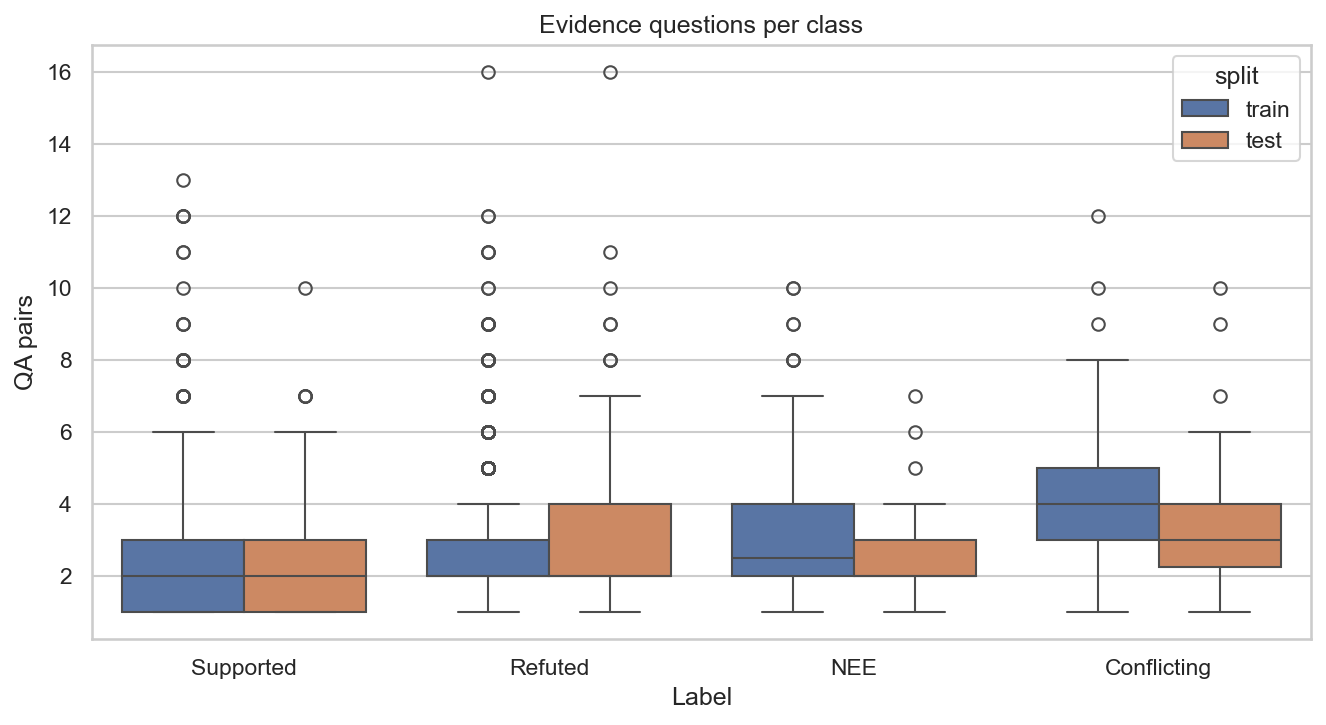

**eda_nee_phrase_check.png**

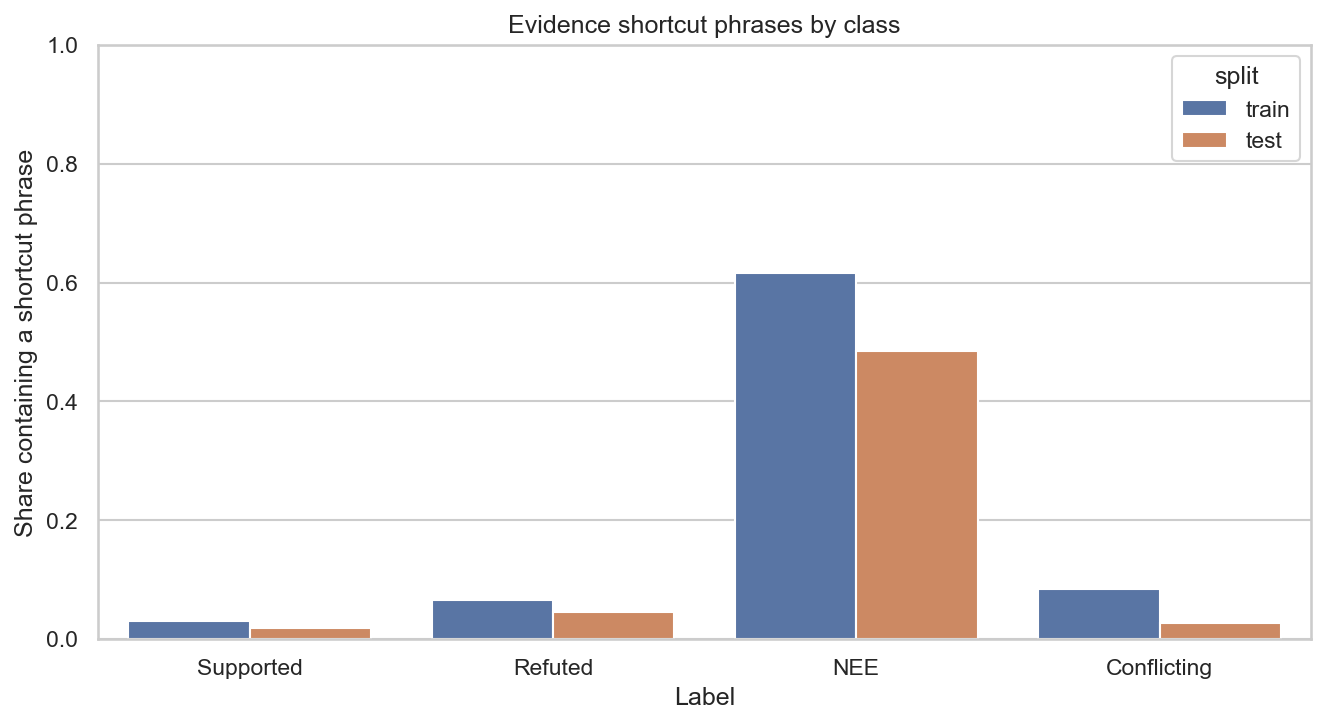

In [3]:
figure_names = [
    "eda_class_distribution.png",
    "eda_claim_length.png",
    "eda_evidence_length.png",
    "eda_missing_evidence_by_class.png",
    "eda_n_qa_by_class.png",
    "eda_nee_phrase_check.png",
]
for name in figure_names:
    display(Markdown(f"**{name}**"))
    display(Image(filename=str(C.FIGURES_DIR / name)))
